In [1]:
import pandas as pd

In [2]:
import requests
from bs4 import BeautifulSoup

In [3]:
headers = {
    
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
}
webpage= requests.get('https://www.ambitionbox.com/list-of-companies?page=1',headers=headers).text

In [4]:
soup = BeautifulSoup(webpage,'lxml')

<!DOCTYPE html>
<html lang="en">
 <head>
  <meta charset="utf-8"/>
  <title>
   Top Companies in India | AmbitionBox
  </title>
  <meta content="Top Companies in India | AmbitionBox" name="title"/>
  <meta content="Get detailed information of top Companies in India shared by employees through reviews, salaries, interview questions, benefits and more." name="description"/>
  <meta content="width=device-width,initial-scale=1, minimum-scale=1, interactive-widget=resizes-content" name="viewport"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_16x16.png" rel="icon" sizes="16x16" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_32x32.png" rel="icon" sizes="32x32" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_48x48.png" rel="icon" sizes="48x48" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/brows
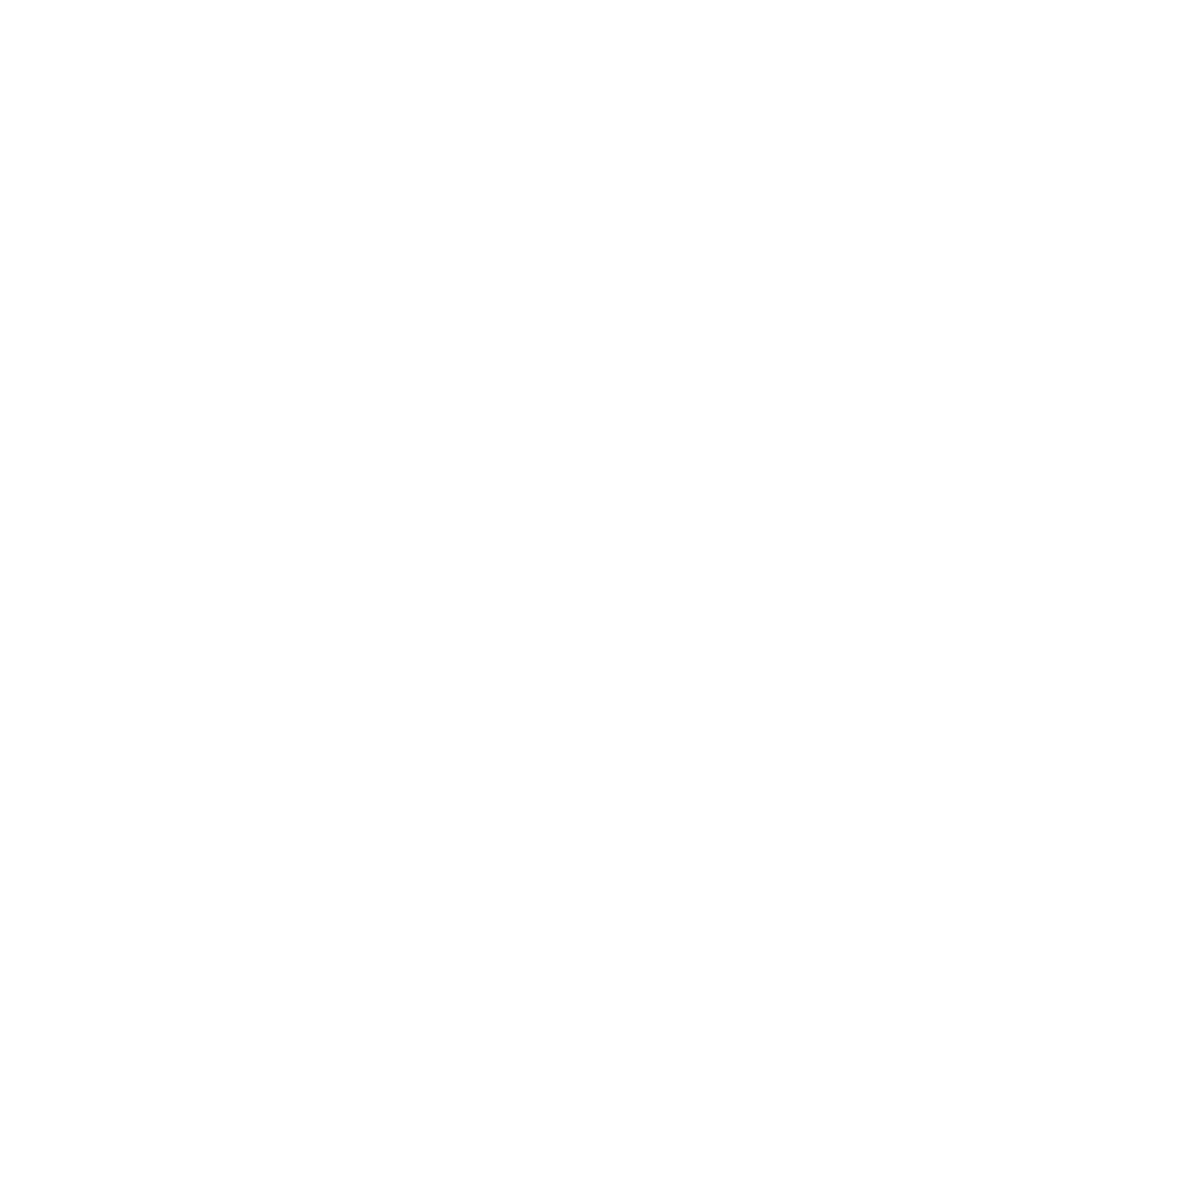

In [5]:
print(soup.prettify())

In [6]:
print(webpage.status_code)
print(webpage.url)
print(soup.title)

AttributeError: 'str' object has no attribute 'status_code'

In [ ]:
for tag in soup.find_all('div'):
    if 'company' in str(tag.get('class', [])).lower():
        print(tag.get('class'))

In [ ]:
print('companyCardWrapper' in webpage.text)print('companyCardWrapper' in webpage.text)

In [ ]:
print(soup.body.prettify()[:10000])

In [ ]:
companies = soup.find_all('div',class_='companycardwrapper')
print(len(companies))

In [ ]:
for company in companies:
    print(company.text.strip())

In [ ]:
company_names = []

for company in companies:
    company_names.append(company.text.strip())

df = pd.DataFrame({
    'Company Name': company_names
})

print(df)

In [ ]:
df.to_csv('companies.csv', index=False)